In [2]:
import numpy as np
from scipy.ndimage import gaussian_filter
from scipy.spatial import ConvexHull, QhullError
from matplotlib.path import Path

import matplotlib.pyplot as plt


def sample_hc(A, R, n_samples=100_000, seed=None, tol=1e-9, max_iter=10_000):
    """Sample intrinsic weights w in [0,1]^A and compute weighted h-categorizer scores.

    Uses x[a] = w[a] / (1 + sum(x[b] for b attacking a)).
    """
    A = list(A)
    if not A or len(set(A)) != len(A):
        raise ValueError("A must contain at least one unique argument.")
    index = {a: i for i, a in enumerate(A)}

    # M[b, a] is 1 when b attacks a.
    M = np.zeros((len(A), len(A)), dtype=float)
    for b, a in R:
        if b not in index or a not in index:
            raise ValueError(f"Attack {(b, a)} contains an argument not in A.")
        M[index[b], index[a]] = 1.0

    rng = np.random.default_rng(seed)
    w = rng.random((n_samples, len(A)))
    x = w.copy()

    # Damping stabilizes fixed-point iteration, especially for cycles.
    for _ in range(max_iter):
        target = w / (1.0 + x @ M)
        x_next = 0.5 * x + 0.5 * target
        if np.max(np.abs(x_next - x)) < tol:
            return w, x_next
        x = x_next

    raise RuntimeError("h-categorizer iteration did not converge.")


# Example framework; replace A and R with the framework to investigate.
A = ["a", "b", "c"]
R = [("a", "b"), ("b", "a"), ("b", "c")]


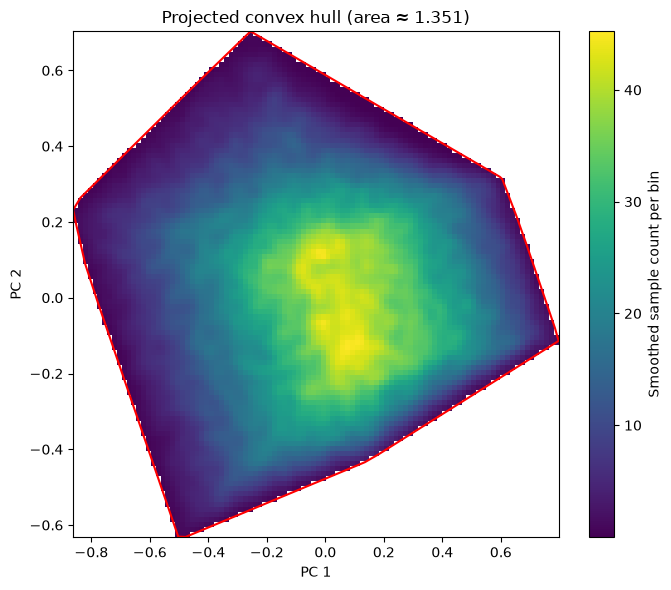

In [3]:

def plot_hc_hull(A, R, n_samples=100_000, seed=0, bins=100):
    w, x = sample_hc(A, R, n_samples=n_samples, seed=seed)
    n_args = len(A)

    if n_args == 1:
        fig, ax = plt.subplots(figsize=(7, 2.5))
        ax.hist(x[:, 0], bins=bins, density=True)
        ax.set_xlabel(f"Acceptability of {A[0]}")
        ax.set_ylabel("Density")
        ax.set_title("h-categorizer acceptability distribution")
        plt.show()
        return w, x

    # For more than two arguments, show the first two principal components.
    if n_args == 2:
        points = x
        labels = [str(A[0]), str(A[1])]
    else:
        centered = x - x.mean(axis=0)
        _, _, vt = np.linalg.svd(centered, full_matrices=False)
        points = centered @ vt[:2].T
        labels = ["PC 1", "PC 2"]

    fig, ax = plt.subplots(figsize=(7, 6))
    try:
        hull = ConvexHull(points)
        polygon = points[hull.vertices]
        hull_path = Path(polygon)
        area = hull.volume  # In 2D, ConvexHull.volume is the area.

        # Estimate density on a grid, then mask bins outside the projected hull.
        H, xedges, yedges = np.histogram2d(
            points[:, 0], points[:, 1], bins=bins
        )
        H = gaussian_filter(H, sigma=1.2)
        xc = (xedges[:-1] + xedges[1:]) / 2
        yc = (yedges[:-1] + yedges[1:]) / 2
        xx, yy = np.meshgrid(xc, yc, indexing="ij")
        inside = hull_path.contains_points(np.c_[xx.ravel(), yy.ravel()])
        H = np.ma.masked_where(~inside.reshape(H.shape), H)

        mesh = ax.pcolormesh(xedges, yedges, H.T, shading="auto", cmap="viridis")
        ax.plot(*np.vstack([polygon, polygon[0]]).T, color="red", linewidth=1.5)
        fig.colorbar(mesh, ax=ax, label="Smoothed sample count per bin")
        ax.set_title(f"Projected convex hull (area ≈ {area:.4g})")
    except QhullError:
        ax.scatter(points[:, 0], points[:, 1], s=2, alpha=0.2)
        ax.set_title("Projected points (degenerate hull)")

    ax.set_xlabel(labels[0])
    ax.set_ylabel(labels[1])
    plt.tight_layout()
    plt.show()
    return w, x


w, x = plot_hc_hull(A, R, n_samples=100_000, seed=0)

In [4]:
frameworks = {
    "mutual pair (2)": (["a", "b"], [("a", "b"), ("b", "a")]),
    "current (3)": (["a", "b", "c"], [("a", "b"), ("b", "a"), ("b", "c")]),
    "chain (4)": (["a", "b", "c", "d"], [("a", "b"), ("b", "c"), ("c", "d")]),
    "star (5)": (["a", "b", "c", "d", "e"], [("a", z) for z in ["b", "c", "d", "e"]]),
    "cycle (6)": (
        ["a", "b", "c", "d", "e", "f"],
        [("a", "b"), ("b", "c"), ("c", "d"), ("d", "e"), ("e", "f"), ("f", "a")],
    ),
}

sample_sizes = [5_000, 20_000, 50_000]
seeds = [1, 2, 3]
bins = 60
results = []

for name, (args, attacks) in frameworks.items():
    # Use one fixed PCA projection and reference heat map for fair comparisons.
    _, x_ref = sample_hc(args, attacks, n_samples=100_000, seed=0)
    centered_ref = x_ref - x_ref.mean(axis=0)
    _, _, vt = np.linalg.svd(centered_ref, full_matrices=False)
    basis = vt[:2].T
    points_ref = centered_ref @ basis

    hull_ref = ConvexHull(points_ref)
    area_ref = hull_ref.volume

    # Fixed grid, with a small margin around the reference sample.
    lo = points_ref.min(axis=0)
    hi = points_ref.max(axis=0)
    margin = 0.02 * (hi - lo)
    ranges = [(lo[i] - margin[i], hi[i] + margin[i]) for i in range(2)]
    edges = [
        np.linspace(ranges[i][0], ranges[i][1], bins + 1)
        for i in range(2)
    ]

    H_ref, _, _ = np.histogram2d(
        points_ref[:, 0], points_ref[:, 1], bins=edges
    )
    H_ref = gaussian_filter(H_ref, sigma=1.2)
    H_ref /= H_ref.sum()

    for n in sample_sizes:
        tv_values = []
        area_errors = []

        for seed in seeds:
            _, x_sample = sample_hc(args, attacks, n_samples=n, seed=seed)
            points = (x_sample - x_ref.mean(axis=0)) @ basis

            H, _, _ = np.histogram2d(
                points[:, 0], points[:, 1], bins=edges
            )
            H = gaussian_filter(H, sigma=1.2)
            H /= H.sum()

            tv_values.append(0.5 * np.abs(H - H_ref).sum())

            try:
                area = ConvexHull(points).volume
                area_errors.append(abs(area - area_ref) / area_ref)
            except QhullError:
                area_errors.append(np.nan)

        results.append(
            (name, n, np.mean(tv_values), np.std(tv_values),
             np.nanmean(area_errors))
        )

print(f"{'Framework':<18} {'N':>8} {'Mean TV':>10} {'TV SD':>10} {'Mean hull error':>17}")
for name, n, tv_mean, tv_sd, area_err in results:
    print(f"{name:<18} {n:>8,} {tv_mean:>10.4f} {tv_sd:>10.4f} {area_err:>16.2%}")

Framework                 N    Mean TV      TV SD   Mean hull error
mutual pair (2)       5,000     0.0602     0.0047            1.50%
mutual pair (2)      20,000     0.0306     0.0007            0.44%
mutual pair (2)      50,000     0.0216     0.0004            0.19%
current (3)           5,000     0.0540     0.0007            6.75%
current (3)          20,000     0.0311     0.0014            3.67%
current (3)          50,000     0.0203     0.0007            2.08%
chain (4)             5,000     0.0562     0.0020            9.82%
chain (4)            20,000     0.0292     0.0005            4.83%
chain (4)            50,000     0.0211     0.0003            2.16%
star (5)              5,000     0.0514     0.0023           12.61%
star (5)             20,000     0.0290     0.0008            5.63%
star (5)             50,000     0.0207     0.0006            1.19%
cycle (6)             5,000     0.0504     0.0009           19.63%
cycle (6)            20,000     0.0263     0.0011            